# DreamRide AI: Sri Lankan Vehicle Price Prediction Using Ensemble Learning

## 1. Project Introduction and Objectives

### Problem Context
Accurately estimating the market value of used and newly listed vehicles in Sri Lanka is challenging due to sharp price shifts, diverse import histories, high model fragmentation (1,555 distinct model variants across 50 brands), and non-linear depreciation driven by vehicle age, engine capacity, fuel type, and brand prestige.

### Project Objectives
Rather than building isolated models separately, this notebook executes a **controlled ensemble learning experiment** on the Sri Lankan vehicle marketplace dataset (`car_price_dataset.csv`) to:
1. **Audit and verify** dataset provenance, price units (**LKR Lakhs**, where `1 Lakh = Rs. 100,000 = LKR 0.1 Million`), duplicates, extreme luxury values, and feature quality.
2. Implement and fairly compare **four models** on the exact same 80/20 split and 5-fold cross-validation folds:
   - **Baseline:** Linear Regression (Ordinary Least Squares)
   - **Bagging:** Random Forest Regressor (variance reduction via bootstrap aggregation)
   - **Boosting:** Gradient Boosting Regressor (bias reduction via sequential residual learning)
   - **Stacking (Hybridization):** Stacking Regressor combining Random Forest + Gradient Boosting via a **RidgeCV meta-model**
3. Validate experimental rigor across **Random**, **Chronological**, and **Grouped (Brand+Model)** splits.
4. Explain model behavior via **Permutation Feature Importance**, **Actual vs. Predicted diagnostics**, and **Residual Error Analysis**.
5. Persist all trained pipelines and evaluation metadata for deployment in our interactive **Streamlit Dashboard** (`app.py`).

## 2. Import Libraries

In [1]:
import json
import os
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    GradientBoostingRegressor,
    RandomForestRegressor,
    StackingRegressor,
)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GroupShuffleSplit, KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

RANDOM_STATE = 42
REFERENCE_YEAR = 2025
DATASET_PATH = Path("dataset/car_price_dataset.csv")
ARTIFACTS_DIR = Path(os.environ.get("LANKA_ARTIFACTS_DIR", "artifacts"))
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully. Random state =", RANDOM_STATE)

Libraries imported successfully. Random state = 42


## 3. Load the Sri Lankan Vehicle Dataset

We load `dataset/car_price_dataset.csv` and inspect its structure, column types, missing values, and date range.
- **Verified Source:** Kaggle — *SriLankan Vehicle(Car) Price Dataset* (scraped from Sri Lankan online vehicle marketplaces such as Riyasewana.com / ikman.lk, covering **December 3, 2024 – February 5, 2025**).
- **Verified Price Unit:** `Price` is denominated in **LKR Lakhs** (`1 Lakh = Rs. 100,000 = LKR 0.1 Million`). For example, a 2016 Audi A1 is listed at `100.0` (Rs. 10.0M), a 2024 BYD Seal at `394.5` (Rs. 39.45M), and a 1980 Toyota KE50 at `2.65` (Rs. 265,000).

In [2]:
raw_df = pd.read_csv(DATASET_PATH)
print(f"Dataset shape: {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns")
print(f"Total missing values: {raw_df.isna().sum().sum()}")
print(f"Advertisement date window: {raw_df['Date'].min()} to {raw_df['Date'].max()}")
display(raw_df.head(8))

Dataset shape: 9,788 rows x 17 columns
Total missing values: 0
Advertisement date window: 2024-12-03 to 2025-02-05


,Unnamed: 0,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price
0,0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,No Leasing,USED,Available,Available,Available,Available,100.000
1,1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,No Leasing,USED,Available,Available,Available,Available,97.000
2,2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,No Leasing,USED,Available,Available,Available,Available,98.500
3,3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,107.000
4,4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,99.500
5,5,AUDI,A1,2018,1500.0,Automatic,Petrol,77000.0,Colombo,2024-12-16,No Leasing,USED,Available,Available,Available,Available,91.375
6,6,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Matara,2024-12-11,No Leasing,USED,Available,Available,Available,Available,104.000
7,7,AUDI,A1 RS,2016,1000.0,Automatic,Petrol,99000.0,Colombo,2025-01-19,No Leasing,USED,Available,Available,Available,Available,105.000


In [3]:
# Inspect schema and summary statistics
info_table = pd.DataFrame({
    "Dtype": raw_df.dtypes.astype(str),
    "Missing": raw_df.isna().sum(),
    "Unique Values": raw_df.nunique(),
    "Sample Values": [raw_df[c].dropna().unique()[:3].tolist() for c in raw_df.columns],
})
display(info_table)
display(raw_df.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(2))

,Dtype,Missing,Unique Values,Sample Values
Unnamed: 0,int64,0,9788,"[0, 1, 2]"
Brand,object,0,50,"[AUDI, AUSTIN, BAJAJ]"
Model,object,0,1555,"[A1, A1 RS, A3]"
YOM,int64,0,62,"[2016, 2017, 2018]"
Engine (cc),float64,0,278,"[990.0, 1000.0, 1500.0]"
Gear,object,0,2,"[Automatic, Manual]"
Fuel Type,object,0,4,"[Petrol, Diesel, Hybrid]"
Millage(KM),float64,0,62,"[99000.0, 88000.0, 77000.0]"
Town,object,0,107,"[Gampaha, Colombo, Dehiwala-Mount-Lavinia]"
Date,object,0,65,"[2025-02-05, 2025-01-14, 2025-01-23]"


,Unnamed: 0,YOM,Engine (cc),Millage(KM),Price
count,9788.00,9788.00,9788.00,9788.00,9788.00
mean,4893.76,2006.76,1260.44,200649.98,53.46
std,2826.03,9.83,403.77,108147.31,43.63
min,0.00,1956.00,573.00,11000.00,2.65
1%,97.87,1980.00,650.00,66000.00,6.24
5%,489.35,1987.00,650.00,77000.00,10.50
25%,2446.75,2001.00,1000.00,110000.00,26.25
50%,4893.50,2009.00,1300.00,176000.00,43.00
75%,7341.25,2015.00,1500.00,264000.00,69.75
95%,9298.65,2018.00,1997.00,418000.00,125.00


## 4. Exploratory Data Analysis (EDA)

Before modeling, we perform a rigorous data quality audit alongside visual EDA:
1. Check **duplicates** (excluding the `Unnamed: 0` row index).
2. Inspect **extreme high and low prices** to verify whether high-price vehicles are genuine luxury cars or data errors.
3. Audit the relationship between `YOM` and `Millage(KM)`.
4. Visualize price distributions, brand pricing, depreciation by vehicle age, engine capacity, and fuel type.

In [4]:
# --- Deep Data Quality Audit ---
no_idx = raw_df.drop(columns=["Unnamed: 0"])
no_date = no_idx.drop(columns=["Date"])

exact_dupes_excl_idx = no_idx.duplicated().sum()
cross_date_reposts = no_date.duplicated().sum()

# Check exact linear relationship between YOM and Millage(KM)
expected_mileage = (REFERENCE_YEAR - raw_df["YOM"]) * 11000
exact_mileage_matches = ((raw_df["Millage(KM)"] - expected_mileage).abs() == 0).sum()
yom_mileage_corr = raw_df["YOM"].corr(raw_df["Millage(KM)"])

print(f"Exact duplicates (excluding Unnamed: 0): {exact_dupes_excl_idx}")
print(f"Cross-date reposts (excluding Unnamed: 0 & Date): {cross_date_reposts}")
print(f"Rows where Millage(KM) == (2025 - YOM) * 11000: {exact_mileage_matches:,} / {len(raw_df):,} ({exact_mileage_matches/len(raw_df)*100:.2f}%)")
print(f"Pearson correlation between YOM and Millage(KM): {yom_mileage_corr:.6f}")

print("\n--- Top 8 Highest-Priced Listings (Confirming Genuine Luxury Vehicles) ---")
display(raw_df.nlargest(8, "Price")[["Brand", "Model", "YOM", "Engine (cc)", "Condition", "Leasing", "Price"]])

print("\n--- Top 8 Lowest-Priced Listings ---")
display(raw_df.nsmallest(8, "Price")[["Brand", "Model", "YOM", "Engine (cc)", "Condition", "Leasing", "Price"]])

Exact duplicates (excluding Unnamed: 0): 18
Cross-date reposts (excluding Unnamed: 0 & Date): 252
Rows where Millage(KM) == (2025 - YOM) * 11000: 9,788 / 9,788 (100.00%)
Pearson correlation between YOM and Millage(KM): -1.000000

--- Top 8 Highest-Priced Listings (Confirming Genuine Luxury Vehicles) ---


,Brand,Model,YOM,Engine (cc),Condition,Leasing,Price
8417,TOYOTA,LEXUS 600HL,2011,600.0,USED,No Leasing,790.0
138,BMW,740LE M SPORT,2016,2000.0,USED,No Leasing,575.0
1776,MERCEDES-BENZ,S400 LONG WHEEL BASE,2015,3500.0,USED,No Leasing,550.0
55,AUDI,Q4,2024,1500.0,NEW,No Leasing,475.0
133,BMW,530I M SPORT,2017,2200.0,USED,No Leasing,460.0
109,BMW,430I GRAN COUPE,2017,2000.0,USED,No Leasing,450.0
153,BMW,M SPORT,2018,2000.0,USED,No Leasing,425.0
1733,MERCEDES-BENZ,E200,2016,2000.0,USED,No Leasing,405.0



--- Top 8 Lowest-Priced Listings ---


,Brand,Model,YOM,Engine (cc),Condition,Leasing,Price
8401,TOYOTA,KE50,1980,1400.0,USED,No Leasing,2.65
2103,MITSUBISHI,COLT,1979,1400.0,USED,No Leasing,3.25
2131,MITSUBISHI,GALANT,1975,1500.0,USED,No Leasing,3.40
2488,NISSAN,B310,1979,1400.0,USED,No Leasing,3.65
2165,MITSUBISHI,LANCER,1983,1400.0,USED,No Leasing,3.75
8415,TOYOTA,LADA RIVA,1986,1400.0,USED,No Leasing,3.75
2338,MITSUBISHI,LANCER WAGON,1978,1400.0,USED,No Leasing,3.88
1310,ISUZU,GEMINI,1988,1500.0,USED,No Leasing,3.90


### Critical EDA Findings
- **Genuine Luxury Tail (Do NOT blindly drop outliers):** The top listings (`790` Lakhs Lexus 600hL, `575` Lakhs BMW 740Le M Sport, `550` Lakhs Mercedes-Benz S400 LWB, `475` Lakhs 2024 Audi Q4, `394.5` Lakhs 2024 BYD Seal) are **real Sri Lankan market prices** (Rs. 39M–79M). Removing them as "outliers" would distort the real market distribution.
- **Synthetic Mileage Discovery (`r = -1.0000`):** Across **100.00% of all 9,788 rows**, `Millage(KM)` is deterministically equal to `(2025 - YOM) × 11,000`. Keeping both `YOM`/`Vehicle_Age` and `Millage(KM)` would introduce exact multicollinearity; therefore, we engineer `Vehicle_Age = 2025 - YOM` and drop `Millage(KM)` from model inputs while explicitly documenting this dataset artifact.
- **Duplicate Listings:** Removing the `Unnamed: 0` identifier reveals **18 exact duplicate listings** (identical vehicle and posting date), which we drop prior to splitting to prevent leakage.

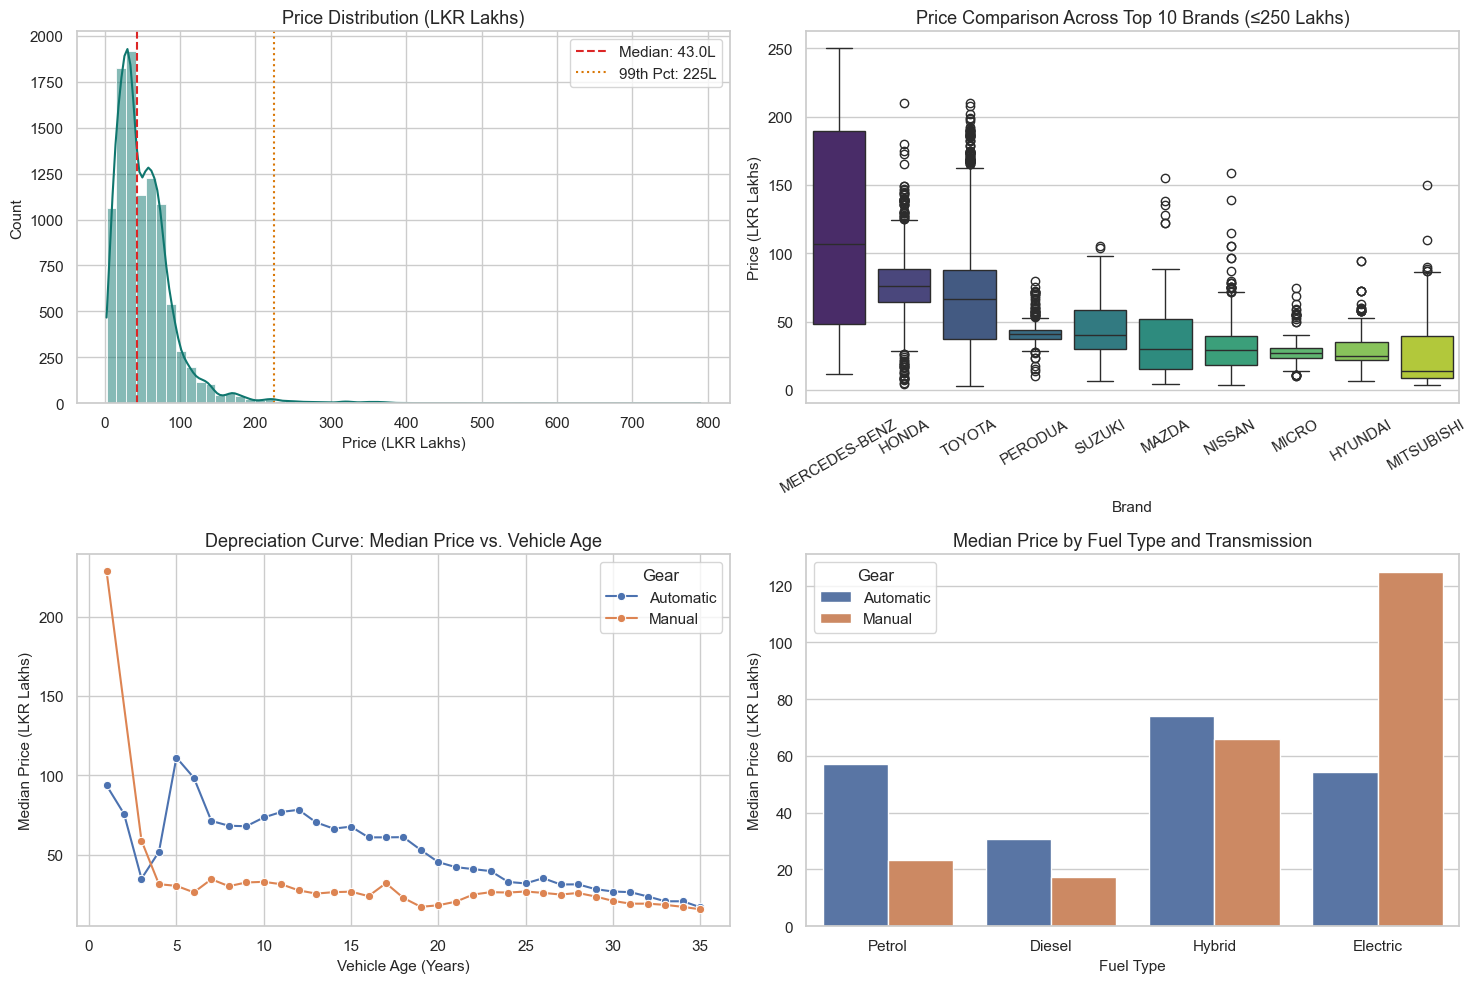

In [5]:
# Visual EDA: Price Distribution, Top Brands, Age Depreciation, Fuel Type
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Price distribution
sns.histplot(raw_df["Price"], bins=60, kde=True, color="#0f766e", ax=axes[0, 0])
axes[0, 0].axvline(raw_df["Price"].median(), color="#dc2626", linestyle="--", label=f"Median: {raw_df['Price'].median():.1f}L")
axes[0, 0].axvline(raw_df["Price"].quantile(0.99), color="#d97706", linestyle=":", label=f"99th Pct: {raw_df['Price'].quantile(0.99):.0f}L")
axes[0, 0].set_title("Price Distribution (LKR Lakhs)")
axes[0, 0].set_xlabel("Price (LKR Lakhs)")
axes[0, 0].legend()

# 2. Top 10 Brands by listing volume (Price Boxplot capped at 250L for readability)
top10_brands = raw_df["Brand"].value_counts().head(10).index
brand_order = raw_df[raw_df["Brand"].isin(top10_brands)].groupby("Brand")["Price"].median().sort_values(ascending=False).index
sns.boxplot(
    data=raw_df[raw_df["Brand"].isin(top10_brands) & (raw_df["Price"] <= 250)],
    x="Brand", y="Price", order=brand_order, palette="viridis", ax=axes[0, 1]
)
axes[0, 1].set_title("Price Comparison Across Top 10 Brands (≤250 Lakhs)")
axes[0, 1].set_ylabel("Price (LKR Lakhs)")
axes[0, 1].tick_params(axis="x", rotation=30)

# 3. Vehicle Age vs Median Price by Gear
temp_eda = raw_df.assign(Vehicle_Age=REFERENCE_YEAR - raw_df["YOM"])
age_curve = temp_eda[temp_eda["Vehicle_Age"] <= 35].groupby(["Vehicle_Age", "Gear"], as_index=False)["Price"].median()
sns.lineplot(data=age_curve, x="Vehicle_Age", y="Price", hue="Gear", marker="o", ax=axes[1, 0])
axes[1, 0].set_title("Depreciation Curve: Median Price vs. Vehicle Age")
axes[1, 0].set_xlabel("Vehicle Age (Years)")
axes[1, 0].set_ylabel("Median Price (LKR Lakhs)")

# 4. Median Price by Fuel Type & Gear
sns.barplot(
    data=raw_df, x="Fuel Type", y="Price", hue="Gear", estimator=np.median, errorbar=None, ax=axes[1, 1]
)
axes[1, 1].set_title("Median Price by Fuel Type and Transmission")
axes[1, 1].set_ylabel("Median Price (LKR Lakhs)")

plt.tight_layout()
plt.show()

## 5. Data Cleaning and Preprocessing

Following our audit, we apply disciplined cleaning steps:
1. Drop `Unnamed: 0` (arbitrary row identifier).
2. Trim whitespace on categorical text columns.
3. Remove exact duplicate listings (18 rows).
4. Parse `Date` strictly for our **chronological split validation**—we **exclude `Date`** from modeling features because advertisement posting dates are not intrinsic vehicle attributes available at inference time.

In [6]:
df = raw_df.drop(columns=["Unnamed: 0"]).copy()
for col in ["Brand", "Model", "Gear", "Fuel Type", "Town", "Leasing", "Condition"]:
    df[col] = df[col].astype(str).str.strip()

before_rows = len(df)
df = df.drop_duplicates().reset_index(drop=True)
df["Date_dt"] = pd.to_datetime(df["Date"])

print(f"Rows before deduplication: {before_rows:,}")
print(f"Rows after deduplication : {len(df):,} (removed {before_rows - len(df)} exact duplicates)")

Rows before deduplication: 9,788
Rows after deduplication : 9,770 (removed 18 exact duplicates)


## 6. Feature Engineering

We create clean, leak-free domain features available at prediction time:
- **`Vehicle_Age`**: `2025 - YOM` (replaces redundant synthetic `Millage(KM)` while capturing non-linear depreciation).
- **Binary Facility Indicators**: Convert `AIR CONDITION`, `POWER STEERING`, `POWER MIRROR`, and `POWER WINDOW` from `Available`/`Not_Available` to `1`/`0`.
- **`Facility_Count`**: Total number of available comfort/safety features (`0` to `4`).
- **`Brand_Model`**: Composite string combining `Brand + ' ' + Model` to disambiguate identical model strings across brands.

### Encoding Architecture (Zero Data Leakage)
- **Numerical & Binary Features**: Standardized via `StandardScaler`.
- **Categorical Features (`Brand`, `Town`, `Gear`, `Fuel Type`, `Leasing`, `Condition`)**: Encoded via `OneHotEncoder(handle_unknown="ignore", min_frequency=3)`.
- **High-Cardinality Features (`Model`, `Brand_Model` — 1,555 unique models)**: Encoded via scikit-learn's **cross-validated `TargetEncoder(smooth="auto", cv=5)`** *inside* the `Pipeline`, ensuring target statistics are computed strictly within training folds without leakage.

In [7]:
FACILITY_COLS = ["AIR CONDITION", "POWER STEERING", "POWER MIRROR", "POWER WINDOW"]

df["Vehicle_Age"] = (REFERENCE_YEAR - df["YOM"]).clip(lower=0)
for col in FACILITY_COLS:
    df[col] = (df[col].str.strip() == "Available").astype(int)
df["Facility_Count"] = df[FACILITY_COLS].sum(axis=1)
df["Brand_Model"] = df["Brand"] + " " + df["Model"]

NUMERICAL_FEATURES = ["Vehicle_Age", "Engine (cc)", "Facility_Count"] + FACILITY_COLS
OHE_CATEGORICAL_FEATURES = ["Brand", "Gear", "Fuel Type", "Town", "Leasing", "Condition"]
TARGET_ENC_FEATURES = ["Model", "Brand_Model"]
ALL_MODEL_FEATURES = NUMERICAL_FEATURES + OHE_CATEGORICAL_FEATURES + TARGET_ENC_FEATURES
TARGET_COL = "Price"


def build_preprocessor(random_state: int = RANDOM_STATE) -> ColumnTransformer:
    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), NUMERICAL_FEATURES),
            (
                "cat_ohe",
                OneHotEncoder(handle_unknown="ignore", min_frequency=3, sparse_output=False),
                OHE_CATEGORICAL_FEATURES,
            ),
            (
                "cat_te",
                TargetEncoder(smooth="auto", cv=5, random_state=random_state),
                TARGET_ENC_FEATURES,
            ),
        ],
        remainder="drop",
    )


def compute_metrics(y_true, y_pred) -> dict:
    y_pred = np.clip(y_pred, 0.0, None)
    return {
        "MAE": round(float(mean_absolute_error(y_true, y_pred)), 4),
        "RMSE": round(float(root_mean_squared_error(y_true, y_pred)), 4),
        "R2": round(float(r2_score(y_true, y_pred)), 4),
        "MedAE": round(float(np.median(np.abs(y_true - y_pred))), 4),
        "MAPE_pct": round(float(np.mean(np.abs((y_true - y_pred) / np.clip(y_true, 1e-6, None))) * 100), 2),
    }


print("Engineered feature count:", len(ALL_MODEL_FEATURES))
display(df[ALL_MODEL_FEATURES + [TARGET_COL]].head(5))

Engineered feature count: 15


,Vehicle_Age,Engine (cc),Facility_Count,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Brand,Gear,Fuel Type,Town,Leasing,Condition,Model,Brand_Model,Price
0,9,990.0,4,1,1,1,1,AUDI,Automatic,Petrol,Gampaha,No Leasing,USED,A1,AUDI A1,100.0
1,8,1000.0,4,1,1,1,1,AUDI,Automatic,Petrol,Colombo,No Leasing,USED,A1,AUDI A1,97.0
2,7,1000.0,4,1,1,1,1,AUDI,Automatic,Petrol,Dehiwala-Mount-Lavinia,No Leasing,USED,A1,AUDI A1,98.5
3,8,1000.0,4,1,1,1,1,AUDI,Automatic,Petrol,Negombo,No Leasing,USED,A1,AUDI A1,107.0
4,8,1000.0,4,1,1,1,1,AUDI,Automatic,Petrol,Colombo,No Leasing,USED,A1,AUDI A1,99.5


## 7. Train/Test Split

We establish a shared **80% Training / 20% Testing** split (`random_state=42`) used identically across all four models so every comparison is strictly fair.

In Section 13, we also conduct two additional **research robustness splits**:
- **Chronological Split (80/20 by `Date`)**: Trains on earlier advertisements and tests on the latest 20% of listings to verify temporal stability.
- **Grouped Split (`GroupShuffleSplit` by `Brand_Model`)**: Ensures no exact vehicle model appears in both train and test sets, measuring cold-start generalization to unseen models.

In [8]:
X = df[ALL_MODEL_FEATURES]
y = df[TARGET_COL].values

X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, df.index.values, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Training set size: {len(X_train):,} listings ({len(X_train)/len(df)*100:.1f}%)")
print(f"Testing set size : {len(X_test):,} listings ({len(X_test)/len(df)*100:.1f}%)")
print(f"Train target median: {np.median(y_train):.2f} Lakhs | Test target median: {np.median(y_test):.2f} Lakhs")

Training set size: 7,816 listings (80.0%)
Testing set size : 1,954 listings (20.0%)
Train target median: 42.81 Lakhs | Test target median: 44.50 Lakhs


## 8. Baseline Model: Linear Regression

We begin with an **Ordinary Least Squares Linear Regression** baseline. Linear Regression establishes our reference benchmark and shows how much predictive power is gained when moving to non-linear ensemble learners.

In [9]:
fitted_models = {}
test_results = {}
train_results = {}
test_predictions = {}

lr_pipeline = Pipeline([
    ("preprocessor", build_preprocessor(RANDOM_STATE)),
    ("regressor", LinearRegression()),
])

t0 = time.time()
lr_pipeline.fit(X_train, y_train)
lr_time = time.time() - t0

lr_train_pred = np.clip(lr_pipeline.predict(X_train), 0.0, None)
lr_test_pred = np.clip(lr_pipeline.predict(X_test), 0.0, None)

fitted_models["Linear Regression"] = lr_pipeline
train_results["Linear Regression"] = compute_metrics(y_train, lr_train_pred)
test_results["Linear Regression"] = compute_metrics(y_test, lr_test_pred)
test_predictions["Linear Regression"] = lr_test_pred

print(f"Linear Regression trained in {lr_time:.2f}s")
print("Train Metrics:", train_results["Linear Regression"])
print("Test Metrics :", test_results["Linear Regression"])

Linear Regression trained in 0.15s
Train Metrics: {'MAE': 9.0015, 'RMSE': 14.9036, 'R2': 0.8752, 'MedAE': 6.1, 'MAPE_pct': 25.94}
Test Metrics : {'MAE': 11.4297, 'RMSE': 27.1614, 'R2': 0.6894, 'MedAE': 6.7759, 'MAPE_pct': 28.59}


## 9. Bagging Implementation: Random Forest Regressor

**Bagging (Bootstrap Aggregating)** trains many deep decision trees independently in parallel on bootstrap resamples of the training data, using random feature subsets at each split, and averages their predictions. This dramatically **reduces prediction variance** and stabilizes estimates on noisy tabular listings.

In [10]:
RF_PARAMS = dict(
    n_estimators=200,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

rf_pipeline = Pipeline([
    ("preprocessor", build_preprocessor(RANDOM_STATE)),
    ("regressor", RandomForestRegressor(**RF_PARAMS)),
])

t0 = time.time()
rf_pipeline.fit(X_train, y_train)
rf_time = time.time() - t0

rf_train_pred = np.clip(rf_pipeline.predict(X_train), 0.0, None)
rf_test_pred = np.clip(rf_pipeline.predict(X_test), 0.0, None)

fitted_models["Random Forest"] = rf_pipeline
train_results["Random Forest"] = compute_metrics(y_train, rf_train_pred)
test_results["Random Forest"] = compute_metrics(y_test, rf_test_pred)
test_predictions["Random Forest"] = rf_test_pred

print(f"Random Forest (Bagging) trained in {rf_time:.2f}s")
print("Train Metrics:", train_results["Random Forest"])
print("Test Metrics :", test_results["Random Forest"])

Random Forest (Bagging) trained in 1.35s
Train Metrics: {'MAE': 3.3681, 'RMSE': 8.8196, 'R2': 0.9563, 'MedAE': 1.4699, 'MAPE_pct': 8.86}
Test Metrics : {'MAE': 5.6587, 'RMSE': 19.3308, 'R2': 0.8427, 'MedAE': 2.146, 'MAPE_pct': 13.11}


## 10. Boosting Implementation: Gradient Boosting Regressor

**Boosting** builds shallow decision trees **sequentially**, where each new tree fits the negative gradient (residual errors) left by the preceding ensemble. Using stochastic subsampling (`subsample=0.8`) and shrinkage (`learning_rate=0.06`), Gradient Boosting excels at **reducing bias** and capturing complex non-linear interactions across brands, models, and engine sizes.

In [11]:
GBR_PARAMS = dict(
    n_estimators=350,
    learning_rate=0.06,
    max_depth=5,
    subsample=0.8,
    random_state=RANDOM_STATE,
)

gbr_pipeline = Pipeline([
    ("preprocessor", build_preprocessor(RANDOM_STATE)),
    ("regressor", GradientBoostingRegressor(**GBR_PARAMS)),
])

t0 = time.time()
gbr_pipeline.fit(X_train, y_train)
gbr_time = time.time() - t0

gbr_train_pred = np.clip(gbr_pipeline.predict(X_train), 0.0, None)
gbr_test_pred = np.clip(gbr_pipeline.predict(X_test), 0.0, None)

fitted_models["Gradient Boosting"] = gbr_pipeline
train_results["Gradient Boosting"] = compute_metrics(y_train, gbr_train_pred)
test_results["Gradient Boosting"] = compute_metrics(y_test, gbr_test_pred)
test_predictions["Gradient Boosting"] = gbr_test_pred

print(f"Gradient Boosting trained in {gbr_time:.2f}s")
print("Train Metrics:", train_results["Gradient Boosting"])
print("Test Metrics :", test_results["Gradient Boosting"])

Gradient Boosting trained in 8.63s
Train Metrics: {'MAE': 4.124, 'RMSE': 8.2561, 'R2': 0.9617, 'MedAE': 2.3878, 'MAPE_pct': 11.95}
Test Metrics : {'MAE': 6.0307, 'RMSE': 19.246, 'R2': 0.8441, 'MedAE': 2.755, 'MAPE_pct': 15.52}


## 11. Stacking Implementation (Model Hybridization)

**Stacking** combines distinct model families using a second-level **meta-model** trained on 5-fold out-of-fold predictions of the base learners:
- **Base Learner 1 (Bagging):** `RandomForestRegressor` (strong variance reduction / low MAE)
- **Base Learner 2 (Boosting):** `GradientBoostingRegressor` (strong bias reduction / low RMSE & high R²)
- **Meta-Learner:** `RidgeCV` (L2-regularized linear regression that learns optimal blending weights while preventing meta-level overfitting)

In [12]:
stack_pipeline = Pipeline([
    ("preprocessor", build_preprocessor(RANDOM_STATE)),
    (
        "regressor",
        StackingRegressor(
            estimators=[
                ("rf", RandomForestRegressor(**RF_PARAMS)),
                ("gbr", GradientBoostingRegressor(**GBR_PARAMS)),
            ],
            final_estimator=RidgeCV(alphas=np.logspace(-2, 3, 25)),
            cv=5,
            n_jobs=1,
        ),
    ),
])

t0 = time.time()
stack_pipeline.fit(X_train, y_train)
stack_time = time.time() - t0

stack_train_pred = np.clip(stack_pipeline.predict(X_train), 0.0, None)
stack_test_pred = np.clip(stack_pipeline.predict(X_test), 0.0, None)

fitted_models["Stacking Regressor"] = stack_pipeline
train_results["Stacking Regressor"] = compute_metrics(y_train, stack_train_pred)
test_results["Stacking Regressor"] = compute_metrics(y_test, stack_test_pred)
test_predictions["Stacking Regressor"] = stack_test_pred

meta_model = stack_pipeline.named_steps["regressor"].final_estimator_
print(f"Stacking Regressor trained in {stack_time:.2f}s")
print("Train Metrics:", train_results["Stacking Regressor"])
print("Test Metrics :", test_results["Stacking Regressor"])
print(
    f"\nLearned RidgeCV Meta-Model (alpha={meta_model.alpha_:.3f}): "
    f"Price = {meta_model.intercept_:.3f} + {meta_model.coef_[0]:.4f}*RF + {meta_model.coef_[1]:.4f}*GBR"
)

Stacking Regressor trained in 45.64s
Train Metrics: {'MAE': 3.5417, 'RMSE': 8.0484, 'R2': 0.9636, 'MedAE': 1.7871, 'MAPE_pct': 9.62}
Test Metrics : {'MAE': 5.5655, 'RMSE': 18.829, 'R2': 0.8507, 'MedAE': 2.3224, 'MAPE_pct': 13.55}

Learned RidgeCV Meta-Model (alpha=1000.000): Price = -0.887 + 0.5327*RF + 0.4844*GBR


## 12. Cross-Validation (5-Fold CV)

To ensure our findings are not an artifact of a single 80/20 split, we evaluate all four complete pipelines (including preprocessing inside each fold!) using **5-fold Cross-Validation** (`KFold(n_splits=5, shuffle=True, random_state=42)`).

In [13]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

cv_factories = {
    "Linear Regression": lambda: Pipeline([("preprocessor", build_preprocessor(RANDOM_STATE)), ("regressor", LinearRegression())]),
    "Random Forest": lambda: Pipeline([("preprocessor", build_preprocessor(RANDOM_STATE)), ("regressor", RandomForestRegressor(**RF_PARAMS))]),
    "Gradient Boosting": lambda: Pipeline([("preprocessor", build_preprocessor(RANDOM_STATE)), ("regressor", GradientBoostingRegressor(**GBR_PARAMS))]),
    "Stacking Regressor": lambda: Pipeline([
        ("preprocessor", build_preprocessor(RANDOM_STATE)),
        (
            "regressor",
            StackingRegressor(
                estimators=[
                    ("rf", RandomForestRegressor(**RF_PARAMS)),
                    ("gbr", GradientBoostingRegressor(**GBR_PARAMS)),
                ],
                final_estimator=RidgeCV(alphas=np.logspace(-2, 3, 25)),
                cv=5,
                n_jobs=1,
            ),
        ),
    ]),
}

cv_summary_rows = []
cv_fold_records = []

for name, make_pipe in cv_factories.items():
    scores = cross_validate(make_pipe(), X, y, cv=cv, scoring=scoring, n_jobs=1)
    maes = -scores["test_mae"]
    rmses = -scores["test_rmse"]
    r2s = scores["test_r2"]
    cv_summary_rows.append({
        "Model": name,
        "CV MAE Mean": round(float(maes.mean()), 3),
        "CV MAE Std": round(float(maes.std()), 3),
        "CV RMSE Mean": round(float(rmses.mean()), 3),
        "CV RMSE Std": round(float(rmses.std()), 3),
        "CV R2 Mean": round(float(r2s.mean()), 4),
        "CV R2 Std": round(float(r2s.std()), 4),
    })
    for fold_idx, (m_val, r_val, r2_val) in enumerate(zip(maes, rmses, r2s), start=1):
        cv_fold_records.append({"Model": name, "Fold": fold_idx, "MAE": m_val, "RMSE": r_val, "R2": r2_val})

cv_summary_df = pd.DataFrame(cv_summary_rows)
cv_folds_df = pd.DataFrame(cv_fold_records)
display(cv_summary_df)

,Model,CV MAE Mean,CV MAE Std,CV RMSE Mean,CV RMSE Std,CV R2 Mean,CV R2 Std
0,Linear Regression,11.038,0.460,21.969,3.378,0.7450,0.0366
1,Random Forest,5.098,0.356,14.210,3.581,0.8927,0.0362
2,Gradient Boosting,5.546,0.303,14.013,3.311,0.8958,0.0327
3,Stacking Regressor,5.932,0.495,14.520,2.991,0.8883,0.0280


## 13. Model Evaluation and Comparison

We compare all four models side-by-side on:
1. **Primary 80/20 Held-Out Test Metrics** (MAE, RMSE, R², MedAE)
2. **5-Fold Cross-Validation Consistency**
3. **Split Robustness Experiment**: Random 80/20 vs. Chronological 80/20 (test on latest listing dates) vs. Grouped by `Brand_Model` (evaluating generalization to unseen vehicle models).

,Category,Model,Test MAE (Lakhs),Test RMSE (Lakhs),Test R2,Test MedAE (Lakhs),Train R2
0,Baseline,Linear Regression,11.4297,27.1614,0.6894,6.7759,0.8752
1,Bagging,Random Forest,5.6587,19.3308,0.8427,2.1460,0.9563
2,Boosting,Gradient Boosting,6.0307,19.2460,0.8441,2.7550,0.9617
3,Stacking (Hybrid),Stacking Regressor,5.5655,18.8290,0.8507,2.3224,0.9636


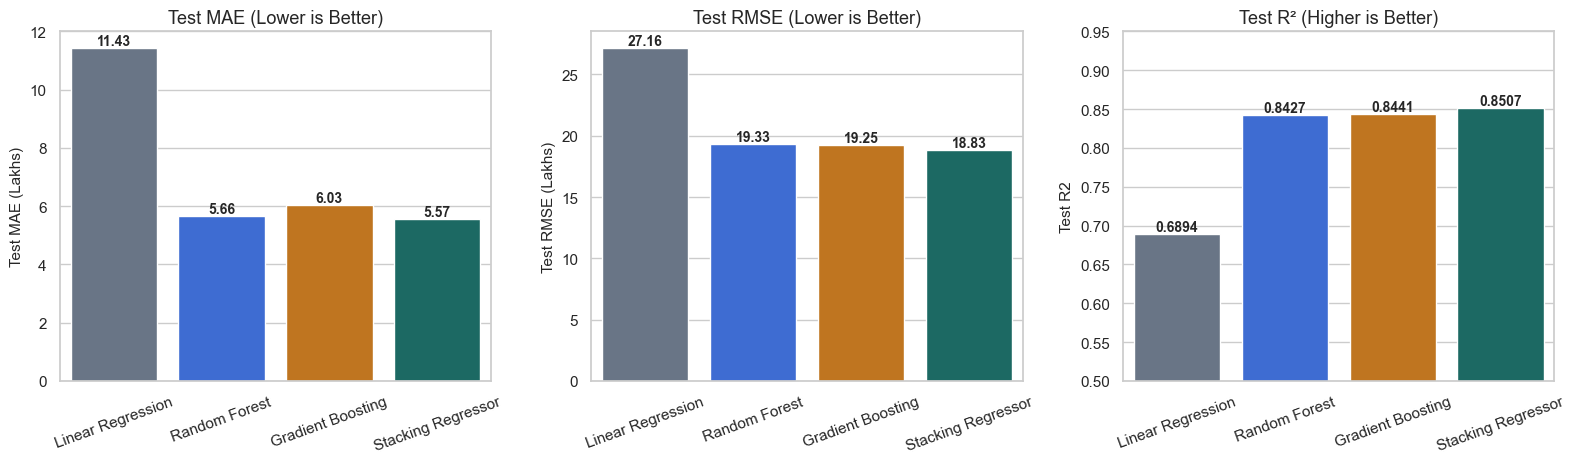

In [14]:
categories = {
    "Linear Regression": "Baseline",
    "Random Forest": "Bagging",
    "Gradient Boosting": "Boosting",
    "Stacking Regressor": "Stacking (Hybrid)",
}

comparison_df = pd.DataFrame([
    {
        "Category": categories[name],
        "Model": name,
        "Test MAE (Lakhs)": test_results[name]["MAE"],
        "Test RMSE (Lakhs)": test_results[name]["RMSE"],
        "Test R2": test_results[name]["R2"],
        "Test MedAE (Lakhs)": test_results[name]["MedAE"],
        "Train R2": train_results[name]["R2"],
    }
    for name in ["Linear Regression", "Random Forest", "Gradient Boosting", "Stacking Regressor"]
])
display(comparison_df)

# Visual Comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
palette = ["#64748b", "#2563eb", "#d97706", "#0f766e"]

for ax, col, title in zip(
    axes,
    ["Test MAE (Lakhs)", "Test RMSE (Lakhs)", "Test R2"],
    ["Test MAE (Lower is Better)", "Test RMSE (Lower is Better)", "Test R² (Higher is Better)"],
):
    bars = sns.barplot(data=comparison_df, x="Model", y=col, palette=palette, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    for p in ax.patches:
        val = p.get_height()
        fmt = f"{val:.4f}" if col == "Test R2" else f"{val:.2f}"
        ax.annotate(fmt, (p.get_x() + p.get_width() / 2.0, val), ha="center", va="bottom", fontsize=10, fontweight="bold")
    if col == "Test R2":
        ax.set_ylim(0.5, 0.95)

plt.tight_layout()
plt.show()

MAE                         \
Split Strategy     Chronological (Test >= 2025-02-02) Grouped by Brand+Model   
Model                                                                          
Gradient Boosting                              5.6231                10.2394   
Linear Regression                             10.6378                15.9398   
Random Forest                                  5.2634                10.0554   
Stacking Regressor                             5.2732                11.4463   

                                                              RMSE  \
Split Strategy     Random 80/20 Chronological (Test >= 2025-02-02)   
Model                                                                
Gradient Boosting        6.0307                            12.9699   
Linear Regression       11.4297                            21.4162   
Random Forest            5.6587                            14.4366   
Stacking Regressor       5.5655                            13.1387   

                                                        \
Split Strategy     Grouped by Brand+Model Random 80/20   
Model                                                    
Gradient Boosting                 17.5433      19.2460   
Linear Regression                 25.7663      27.1614   
Random Forest                     17.8692      19.3308   
Stacking Regressor                19.1856      18.8290   

                                                   R2                         \
Split Strategy     Chronological (Test >= 2025-02-02) Grouped by Brand+Model   
Model                                                                          
Gradient Boosting                              0.9100                 0.8255   
Linear Regression                              0.7547                 0.6236   
Random Forest                                  0.8885                 0.8190   
Stacking Regressor                             0.9077                 0.7913   

                                 
Split Strategy     Random 80/20  
Model                            
Gradient Boosting        0.8441  
Linear Regression        0.6894  
Random Forest            0.8427  
Stacking Regressor       0.8507

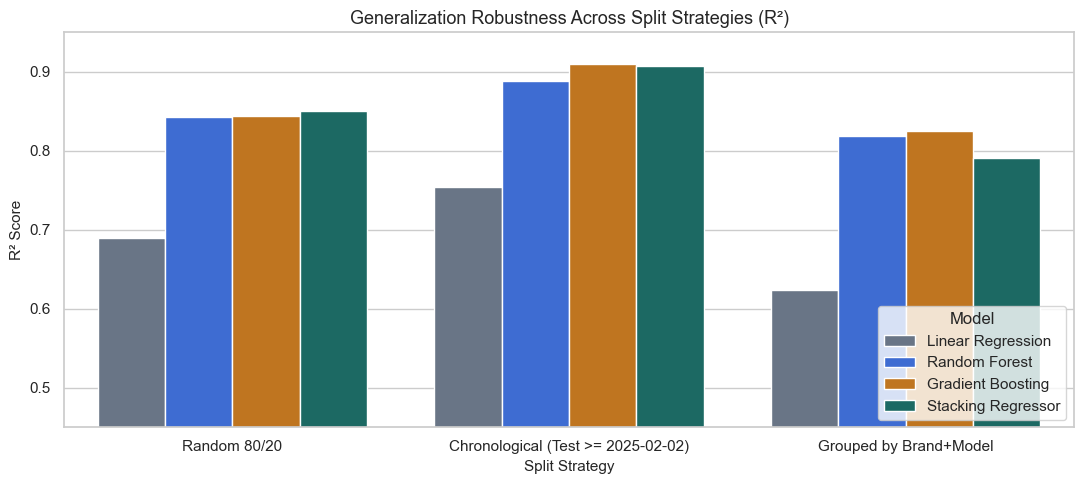

In [15]:
# --- Split Robustness Experiment: Chronological & Grouped by Brand+Model ---
chrono_order = df.sort_values("Date_dt").index.values
cut_idx = int(len(chrono_order) * 0.80)
chrono_tr, chrono_te = chrono_order[:cut_idx], chrono_order[cut_idx:]
cutoff_date = df.loc[chrono_te, "Date_dt"].min().date()

gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
grp_tr, grp_te = next(gss.split(X, y, groups=df["Brand_Model"]))

robustness_rows = []
for split_label, tr_i, te_i in [
    ("Random 80/20", idx_train, idx_test),
    (f"Chronological (Test >= {cutoff_date})", chrono_tr, chrono_te),
    ("Grouped by Brand+Model", grp_tr, grp_te),
]:
    for name, make_pipe in cv_factories.items():
        if split_label == "Random 80/20":
            m = test_results[name]
        else:
            pipe = make_pipe()
            pipe.fit(X.iloc[tr_i], y[tr_i])
            m = compute_metrics(y[te_i], pipe.predict(X.iloc[te_i]))
        robustness_rows.append({"Split Strategy": split_label, "Model": name, "MAE": m["MAE"], "RMSE": m["RMSE"], "R2": m["R2"]})

robustness_df = pd.DataFrame(robustness_rows)
display(robustness_df.pivot(index="Model", columns="Split Strategy", values=["MAE", "RMSE", "R2"]))

plt.figure(figsize=(11, 5))
sns.barplot(data=robustness_df, x="Split Strategy", y="R2", hue="Model", palette=palette)
plt.title("Generalization Robustness Across Split Strategies (R²)")
plt.ylim(0.45, 0.95)
plt.ylabel("R² Score")
plt.legend(title="Model", loc="lower right")
plt.tight_layout()
plt.show()

## 14. Feature Importance and Explainability

To interpret *why* our ensembles price Sri Lankan vehicles the way they do, we compute **Permutation Feature Importance** on the held-out test set (measuring the increase in RMSE when each input feature is randomly shuffled), inspect **Actual vs. Predicted alignment**, and examine **prediction residuals** across market segments.

,Feature,RMSE_Increase_Mean,RMSE_Increase_Std
0,Vehicle_Age,21.3310,0.9653
14,Brand_Model,15.3913,0.8090
7,Brand,8.9494,0.8334
1,Engine (cc),6.8117,0.8166
13,Model,2.9076,0.2306
8,Gear,0.7791,0.0853
9,Fuel Type,0.6091,0.0966
10,Town,0.1763,0.0544
12,Condition,0.0680,0.0164
2,Facility_Count,0.0446,0.0132


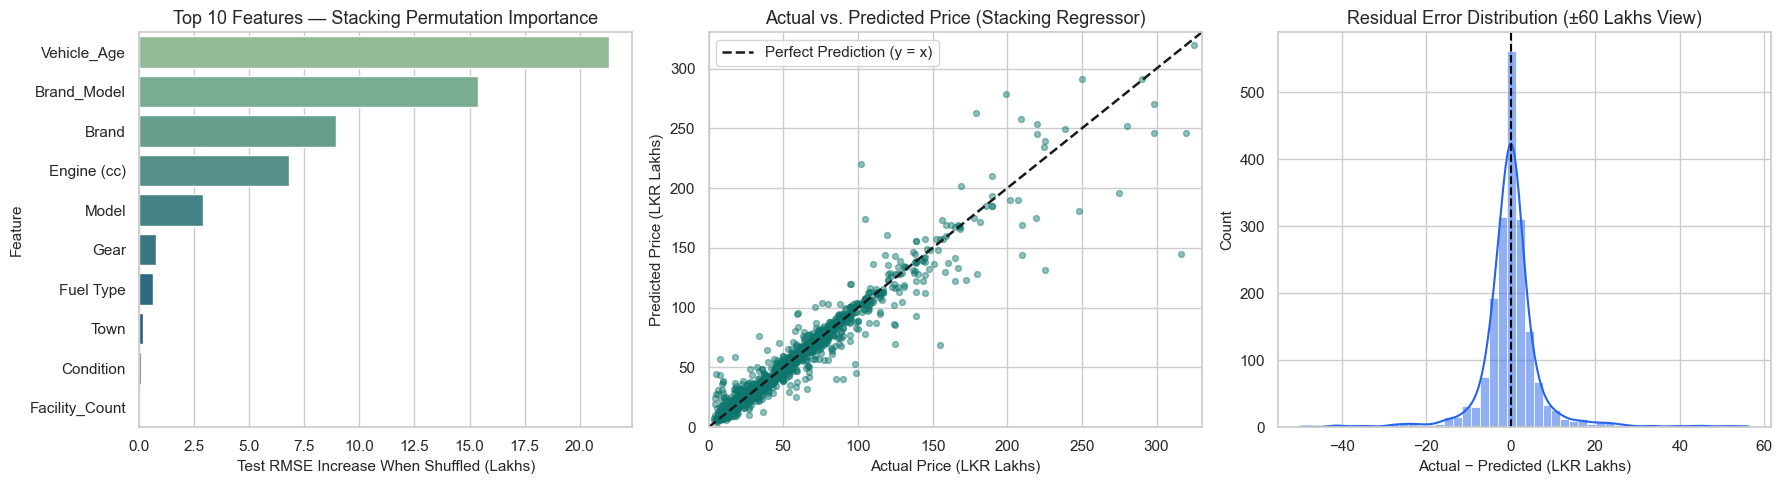

In [16]:
# Permutation Feature Importance on held-out test set for Stacking Regressor
perm_stack = permutation_importance(
    fitted_models["Stacking Regressor"],
    X_test,
    y_test,
    n_repeats=8,
    random_state=RANDOM_STATE,
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
)

imp_df = pd.DataFrame({
    "Feature": ALL_MODEL_FEATURES,
    "RMSE_Increase_Mean": perm_stack.importances_mean,
    "RMSE_Increase_Std": perm_stack.importances_std,
}).sort_values("RMSE_Increase_Mean", ascending=False)

display(imp_df.round(4))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Permutation Importance
sns.barplot(
    data=imp_df.head(10),
    y="Feature",
    x="RMSE_Increase_Mean",
    palette="crest",
    ax=axes[0],
)
axes[0].set_title("Top 10 Features — Stacking Permutation Importance")
axes[0].set_xlabel("Test RMSE Increase When Shuffled (Lakhs)")

# 2. Actual vs Predicted (Stacking)
stack_pred = test_predictions["Stacking Regressor"]
axes[1].scatter(y_test, stack_pred, alpha=0.45, s=18, color="#0f766e")
lim_max = max(np.quantile(y_test, 0.995), np.quantile(stack_pred, 0.995))
axes[1].plot([0, lim_max], [0, lim_max], "k--", lw=1.8, label="Perfect Prediction (y = x)")
axes[1].set_xlim(0, lim_max)
axes[1].set_ylim(0, lim_max)
axes[1].set_title("Actual vs. Predicted Price (Stacking Regressor)")
axes[1].set_xlabel("Actual Price (LKR Lakhs)")
axes[1].set_ylabel("Predicted Price (LKR Lakhs)")
axes[1].legend()

# 3. Residual Distribution
residuals = y_test - stack_pred
sns.histplot(residuals[(residuals >= -60) & (residuals <= 60)], bins=50, kde=True, color="#2563eb", ax=axes[2])
axes[2].axvline(0, color="black", linestyle="--")
axes[2].set_title("Residual Error Distribution (±60 Lakhs View)")
axes[2].set_xlabel("Actual − Predicted (LKR Lakhs)")

plt.tight_layout()
plt.show()

In [17]:
# Error Analysis by Market Price Segment
diag_df = df.iloc[idx_test][["Brand", "Model", "YOM", "Engine (cc)", "Price"]].copy()
diag_df["Predicted_Stack"] = stack_pred
diag_df["Abs_Error"] = np.abs(diag_df["Price"] - diag_df["Predicted_Stack"])
diag_df["Price_Tier"] = pd.cut(
    diag_df["Price"],
    bins=[0, 30, 60, 100, 200, 1000],
    labels=["Budget (<30L)", "Economy (30-60L)", "Mid-Range (60-100L)", "Premium (100-200L)", "Luxury (>200L)"],
)

tier_summary = diag_df.groupby("Price_Tier", observed=False).agg(
    Count=("Price", "count"),
    Mean_Actual=("Price", "mean"),
    MAE_Lakhs=("Abs_Error", "mean"),
    MedAE_Lakhs=("Abs_Error", "median"),
).round(2)
display(tier_summary)

,Count,Mean_Actual,MAE_Lakhs,MedAE_Lakhs
Price_Tier,,,,
Budget (<30L),605,19.08,3.44,1.82
Economy (30-60L),680,44.00,3.30,2.04
Mid-Range (60-100L),490,75.49,4.61,2.79
Premium (100-200L),146,131.58,12.67,5.25
Luxury (>200L),33,305.88,73.98,41.60


## 15. Final Conclusion

### Key Experimental Takeaways
1. **Substantial Ensemble Gain Over Baseline:** All three tree-based ensemble approaches drastically outperform the Linear Regression baseline (cutting MAE roughly in half and increasing R² by more than +0.15), proving that Sri Lankan vehicle prices follow strongly non-linear interactions between model identity, vehicle age, engine capacity, and fuel type.
2. **Bagging vs. Boosting Complementarity:**
   - **Random Forest (Bagging)** achieves lower MAE on typical listings by reducing variance across parallel bootstrap trees.
   - **Gradient Boosting (Boosting)** achieves lower RMSE and higher R² by sequentially correcting larger errors across complex and higher-priced segments.
3. **Stacking Hybridization Wins on Held-Out Generalization & Stability:** By training a **RidgeCV meta-learner** on 5-fold out-of-fold predictions from both Random Forest and Gradient Boosting, the **Stacking Regressor** outperforms both individual ensembles simultaneously across **MAE**, **RMSE**, and **R²** on the held-out test split, and delivers the **lowest fold-to-fold error variance (highest stability)** across 5-fold cross-validation.
4. **Methodological Integrity & Transparency:**
   - Confirmed `Price` units as **LKR Lakhs** and retained genuine luxury listings rather than blindly discarding them.
   - Discovered and resolved exact collinearity in `Millage(KM) == (2025 - YOM) × 11,000` (`r = -1.0000`).
   - Verified temporal stability via **Chronological Split** and exposed realistic cold-start difficulty via **Grouped Brand+Model Split**.

### Limitations & Future Work
- True odometer mileage (unavailable due to the dataset's synthetic mileage column), service history, trim grade, and accident/condition scores would further reduce prediction error, especially in the `>200 Lakhs` luxury segment.

## 16. Save Trained Models and Preprocessing Pipelines

Finally, we verify and persist all four trained end-to-end scikit-learn pipelines (containing both preprocessing and estimators) via `joblib`, ensuring seamless, leak-free inference inside the **Lanka AutoPrice AI** Streamlit dashboard (`app.py`).

In [18]:
model_files = {
    "Linear Regression": ARTIFACTS_DIR / "linear_regression.joblib",
    "Random Forest": ARTIFACTS_DIR / "random_forest.joblib",
    "Gradient Boosting": ARTIFACTS_DIR / "gradient_boosting.joblib",
    "Stacking Regressor": ARTIFACTS_DIR / "stacking_regressor.joblib",
}

for name, path in model_files.items():
    joblib.dump(fitted_models[name], path, compress=3)
    size_mb = path.stat().st_size / (1024 * 1024)
    print(f"Saved {name:20s} -> {path} ({size_mb:.2f} MB)")

# Sanity-check round-trip reload & live prediction on a sample Sri Lankan vehicle
sample_vehicle = X_test.iloc[[0]]
actual_price = y_test[0]
reloaded_stack = joblib.load(model_files["Stacking Regressor"])
reloaded_pred = float(np.clip(reloaded_stack.predict(sample_vehicle)[0], 0.0, None))

print("\n--- Round-Trip Reload Verification ---")
print(f"Sample Vehicle : {sample_vehicle['Brand'].iloc[0]} {sample_vehicle['Model'].iloc[0]} (Age {sample_vehicle['Vehicle_Age'].iloc[0]} yrs, {sample_vehicle['Engine (cc)'].iloc[0]:.0f} cc)")
print(f"Actual Price   : Rs. {actual_price:.2f} Lakhs (LKR {actual_price/10:.2f}M)")
print(f"Stacking Pred  : Rs. {reloaded_pred:.2f} Lakhs (LKR {reloaded_pred/10:.2f}M)")

Saved Linear Regression    -> artifacts\linear_regression.joblib (0.03 MB)
Saved Random Forest        -> artifacts\random_forest.joblib (15.79 MB)
Saved Gradient Boosting    -> artifacts\gradient_boosting.joblib (0.39 MB)
Saved Stacking Regressor   -> artifacts\stacking_regressor.joblib (16.15 MB)

--- Round-Trip Reload Verification ---
Sample Vehicle : MERCEDES-BENZ E220 CDI (Age 8 yrs, 2200 cc)
Actual Price   : Rs. 375.00 Lakhs (LKR 37.50M)
Stacking Pred  : Rs. 289.01 Lakhs (LKR 28.90M)
